In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import corner

import glob
import numpy as np




In [2]:
for path in glob.glob("*.npy.npz"):
    print(path)

mc0.npy.npz
mc1.npy.npz
mc2.npy.npz
mc3.npy.npz
mc4.npy.npz
mc5.npy.npz
mc6.npy.npz
mc7.npy.npz
mc8.npy.npz
mc9.npy.npz
mc10.npy.npz
mc11.npy.npz
mc12.npy.npz
mc13.npy.npz
mc14.npy.npz
mc20.npy.npz
mc21.npy.npz
mc22.npy.npz
mc23.npy.npz
mc24.npy.npz
mc25.npy.npz
mc26.npy.npz
mc27.npy.npz
mc28.npy.npz
mc29.npy.npz
mc30.npy.npz
mc31.npy.npz
mc32.npy.npz
mc33.npy.npz
mc34.npy.npz
mc35.npy.npz
mc36.npy.npz
mc37.npy.npz
mc38.npy.npz
mc39.npy.npz
mc40.npy.npz
mc41.npy.npz
mc42.npy.npz
mc43.npy.npz
mc44.npy.npz


In [3]:
loc=['mc0.npy.npz','mc1.npy.npz']

mc0.npy.npz
1


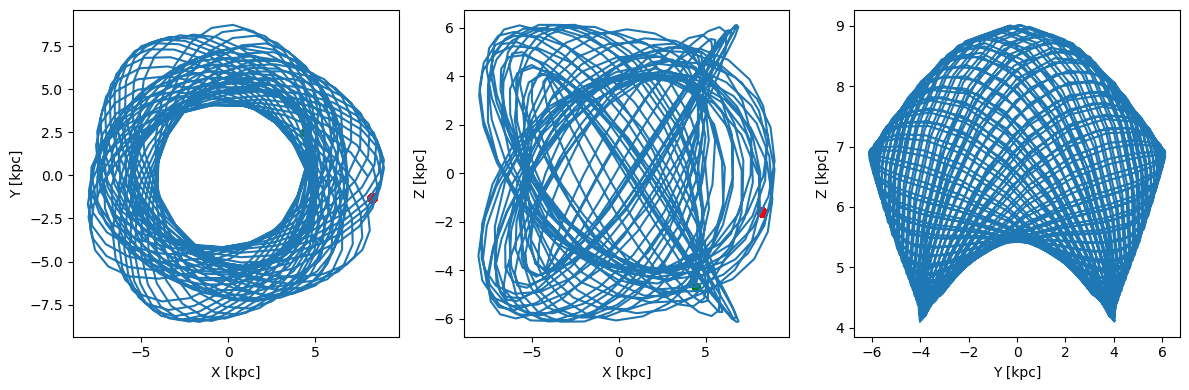

[1.95809579e-05 2.15349477e-06 2.49070421e-07]
2.1760033650056417e-13
mc1.npy.npz
1


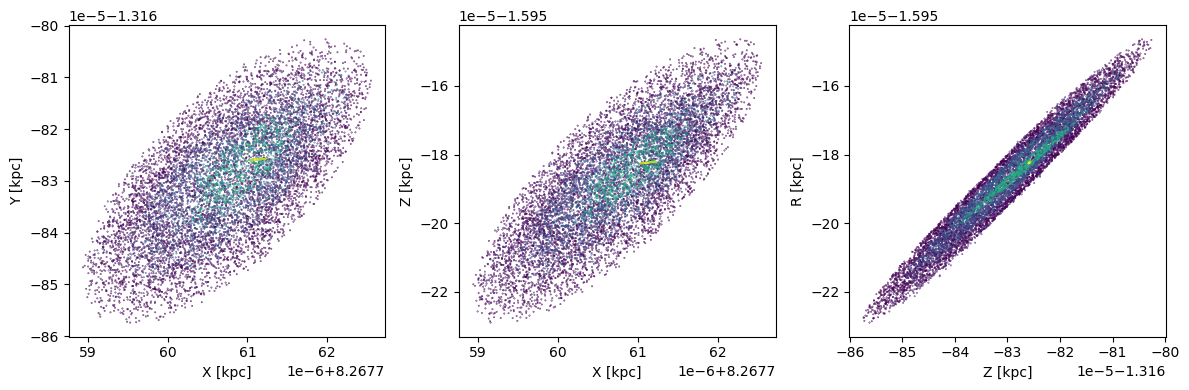

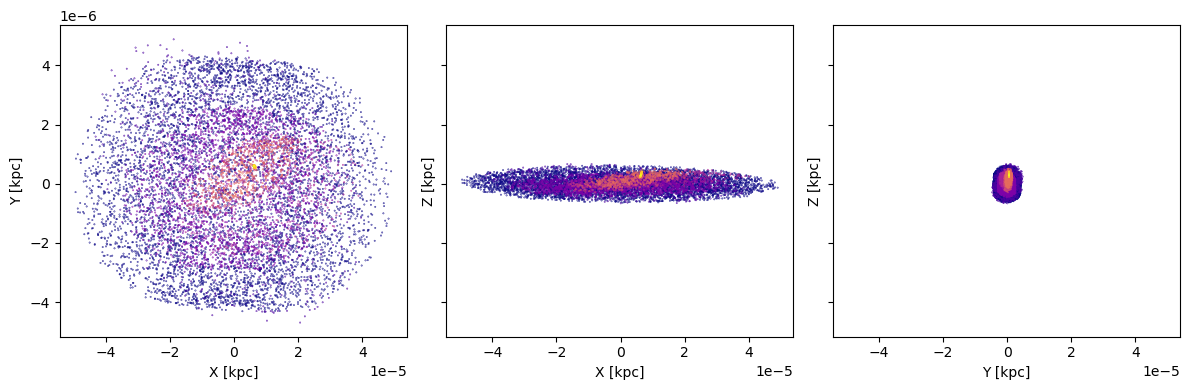

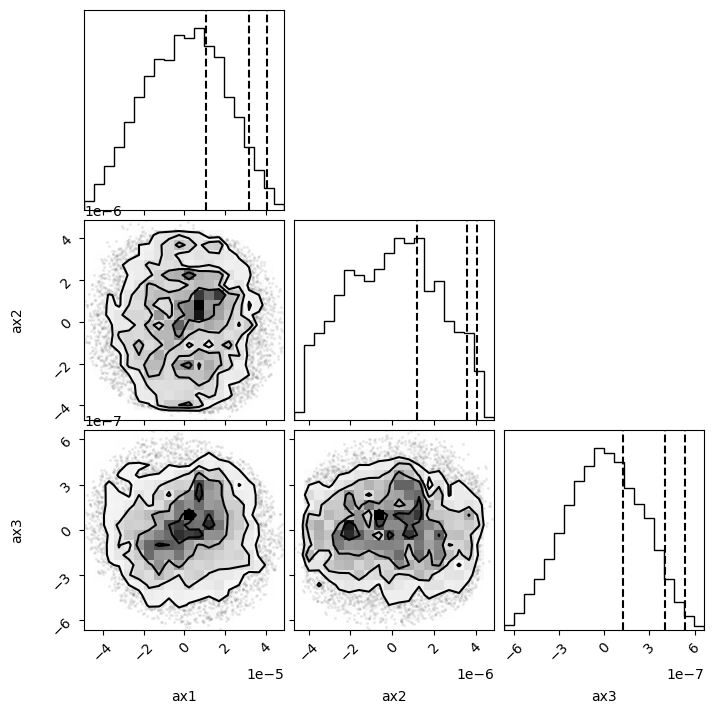

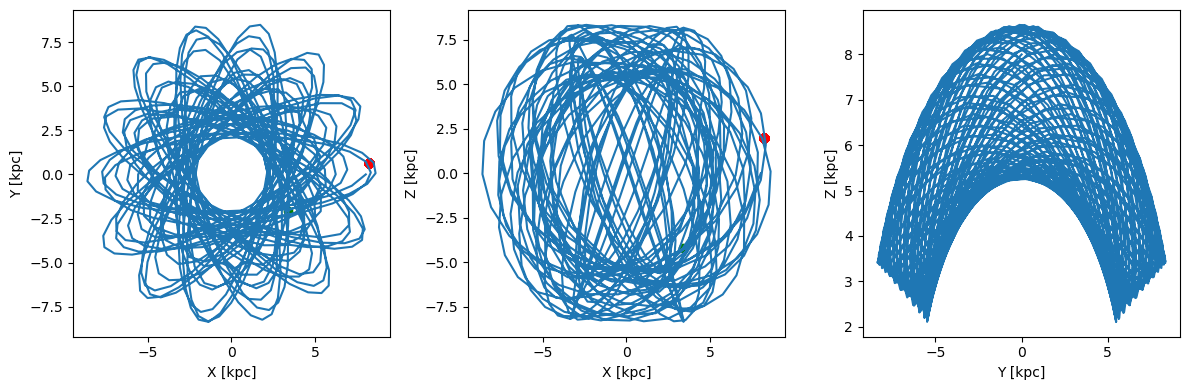

[9.98378098e-06 8.50554084e-07 8.36957960e-08]
2.469026337600226e-14


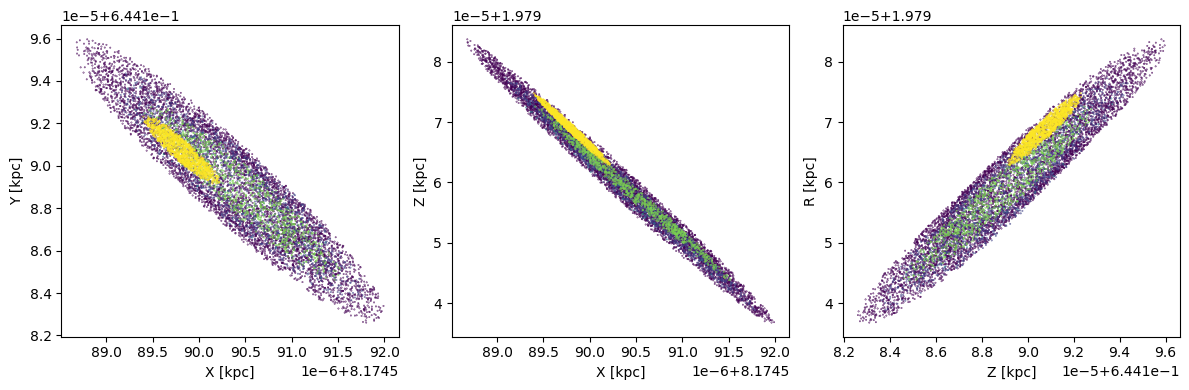

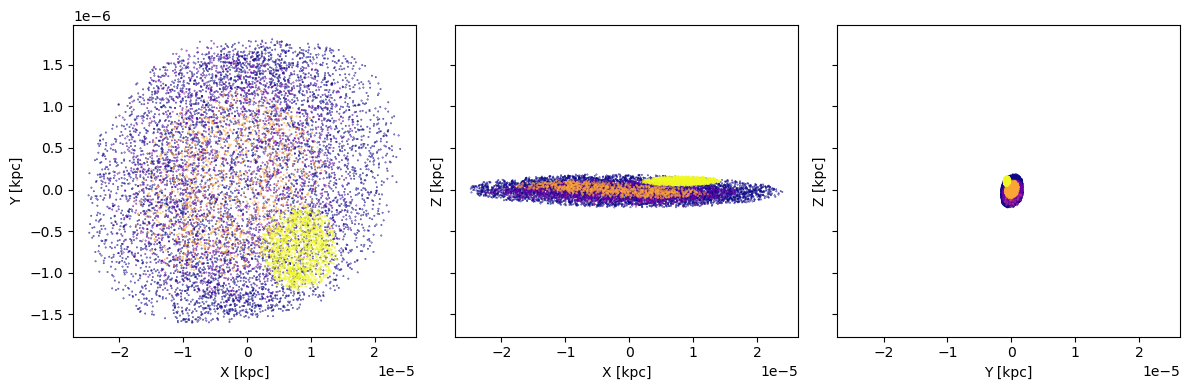

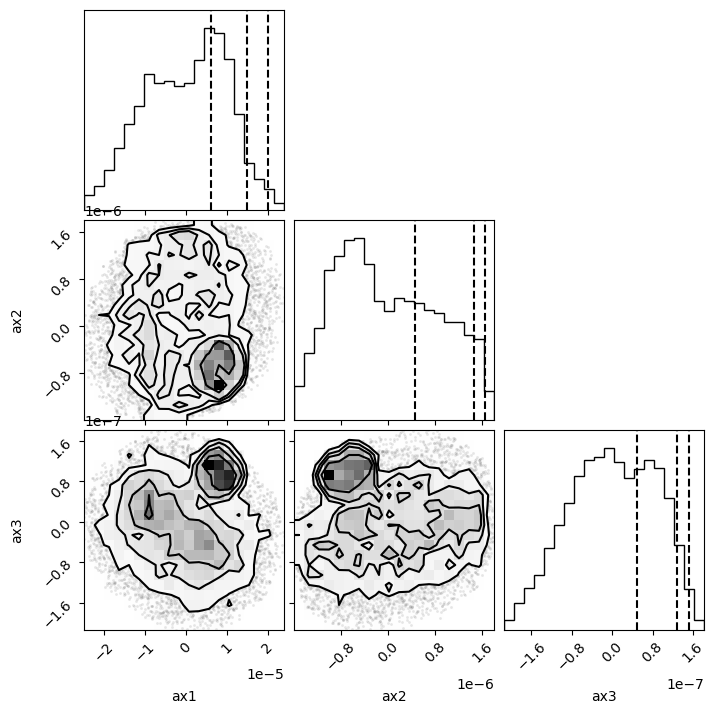

In [4]:

#for path in glob.glob("*.npy.npz"):
#loc=['mc0.npy.npz']
for path in loc:
    print(path)

    d = np.load(path)

    mcp_xv     = d['mcp_xv']
    mcp_mass   = d['mcp_mass']
    mc_mass    = d['mc_mass']
    mc_radius  = d['mc_radius']
    color      = d['color']
    mc_start   = d['mc_start']
    mc_end     = d['mc_end']
    t          = d['t_array']
    o          = d['orbit_array']
    alive=d['alive']
    fig,ax=plt.subplots(1,3,figsize=(12,4))
    print(alive)
    ax[0].plot(o[:,0],o[:,1])
    ax[0].scatter(mc_end[0],mc_end[1],c='orange',marker='*')
    ax[0].scatter(mc_start[0],mc_start[1],c='green')
    ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],c='r')
    ax[0].set_xlabel('X [kpc]')
    ax[0].set_ylabel('Y [kpc]')


    ax[1].plot(o[:,0],o[:,2])
    ax[1].scatter(mc_end[0],mc_end[2],c='orange',marker='*')
    ax[1].scatter(mc_start[0],mc_start[2],c='green')
    ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],c='r')
    ax[1].set_xlabel('X [kpc]')
    ax[1].set_ylabel('Z [kpc]')

    ax[2].plot(o[:,2],np.linalg.norm(o[:,:2],axis=1))
    ax[2].set_xlabel('Y [kpc]')
    ax[2].set_ylabel('Z [kpc]')


    plt.tight_layout()
    plt.show()

    
    fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0)

    ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.1,c=color,cmap='viridis')
    ax[0].set_xlabel('X [kpc]')
    ax[0].set_ylabel('Y [kpc]')

    ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
    ax[1].set_xlabel('X [kpc]')
    ax[1].set_ylabel('Z [kpc]')

    ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
    ax[2].set_xlabel('Z [kpc]')
    ax[2].set_ylabel('R [kpc]')

    plt.tight_layout()
    #plt.show()

    mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
    pca=PCA(n_components=3)
    mcp_xr=pca.fit_transform(mcp_xc)



    print(pca.explained_variance_**0.5)
    fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)

    ax[0].scatter(mcp_xr[:,0],mcp_xr[:,1],s=0.1,c=color,cmap='plasma')
    ax[0].set_xlabel('X [kpc]')
    ax[0].set_ylabel('Y [kpc]')

    ax[1].scatter(mcp_xr[:,0],mcp_xr[:,2],s=0.1,c=color,cmap='plasma')
    ax[1].set_xlabel('X [kpc]')
    ax[1].set_ylabel('Z [kpc]')

    ax[2].scatter(mcp_xr[:,1],mcp_xr[:,2],s=0.1,c=color,cmap='plasma')
    ax[2].set_xlabel('Y [kpc]')
    ax[2].set_ylabel('Z [kpc]')

    plt.tight_layout()
    print(mc_mass)
    #plt.show()
    figure=corner.corner(mcp_xr,labels=['ax1','ax2','ax3'],axes_scale='linear',quantiles=[0.68,0.95,0.99])